####Cell 1: Library


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

####Cell 2 : Data Sintetis

In [8]:
np.random.seed(2026)
n_samples = 100

X1 = np.random.rand(n_samples) * 2
X2 = np.random.rand(n_samples) * 2

noise = np.random.rand(n_samples) * 1.5

#pengaruh linear: Y = 5 + 3.5*X1 -2*X2 + noise
y = 5 + 3.5 * X1 - 2 * X2 + noise

#menggabungkan menjadi data frame
df = pd.DataFrame({'X1': X1, 'X2': X2, 'Y': y})
display(df.head())

,X1,X2,Y
0,0.438691,1.864256,3.206134
1,0.826023,0.607449,7.912705
2,1.953271,1.864547,8.150444
3,0.177798,0.866275,4.171303
4,0.958580,0.647634,7.117771


####Cell 3: Model Fit

In [11]:
X = df[['X1', 'X2']]
y = df['Y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept: {model.intercept_:.4f}")
print(f"Coefficients X1: {model.coef_[0]:.4f}")
print(f"Coefficients X2: {model.coef_[1]:.4f}")

# Y = 5.9284 + 3.428 X1 - 2.159 X2

Intercept: 5.9284
Coefficients X1: 3.4275
Coefficients X2: -2.1587


####Cell 4 : Prediksi dan Matriks

In [12]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-squared: {r2:.4f}")

Mean Squared Error: 0.2552
R-squared: 0.9631


####Cell 5 : Visualisasi

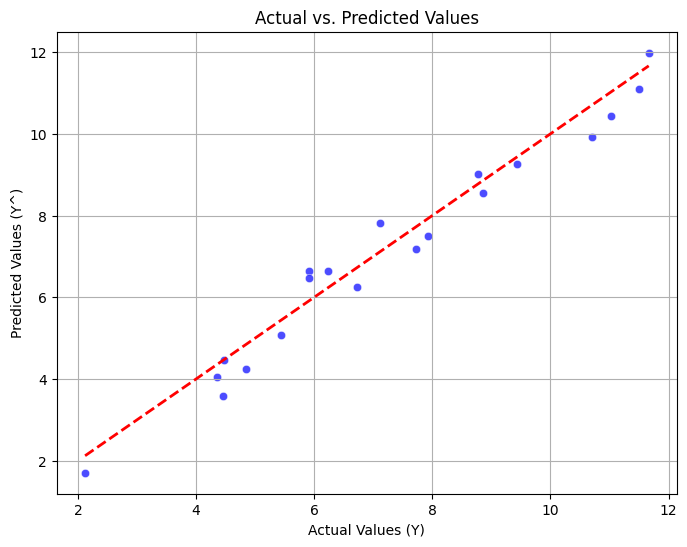

In [16]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', lw=2)
plt.xlabel('Actual Values (Y)')
plt.ylabel('Predicted Values (Y^)')
plt.title('Actual vs. Predicted Values')
plt.grid(True)
plt.show()

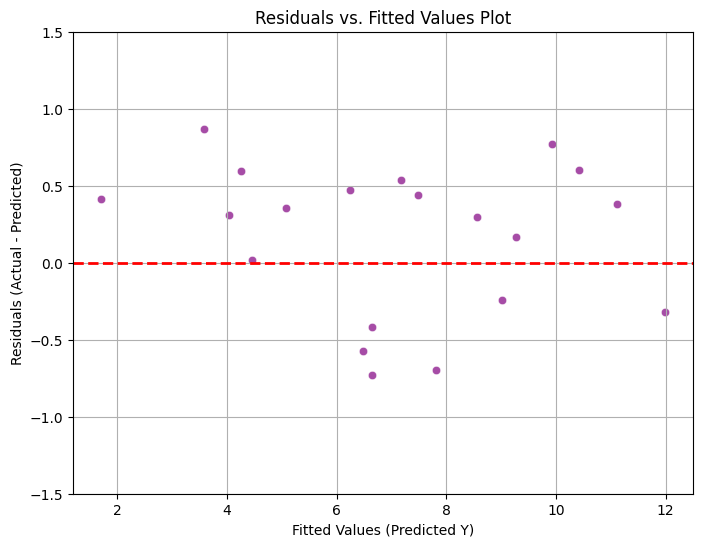

In [18]:
# Menghitung residual (sisaan)
residuals = y_test - y_pred

# Membuat plot Residual vs. Fitted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred, y=residuals, color='purple', alpha=0.7)

# Menambahkan garis horizontal di y=0 sebagai acuan
plt.axhline(y=0, color='red', linestyle='--', lw=2)

plt.xlabel('Fitted Values (Predicted Y)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residuals vs. Fitted Values Plot')
plt.grid(True)
plt.show()